# 02 — From-scratch NumPy MLP (T2)

One-hidden-layer MLP for RUL regression, written with NumPy only (no automatic differentiation). Implementation: `src/numpy_mlp.py`; configuration: `configs/numpy_mlp.json`.

**Reduced representation.** Each 30-cycle × 14-sensor window is summarised by the per-sensor **mean** and **least-squares slope** over the window (28 inputs), standardised with training-engine statistics. Targets are divided by the RUL cap (125) so the network outputs values in [0, 1]. This model is separate from the two framework models in T3. The test set is not used in this notebook.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import data
from src.numpy_mlp import NumpyMLP, train, gradient_check
from scripts.train_numpy_mlp import load_inputs

FIG = ROOT / 'results' / 'figures'
cfg = data.load_config(ROOT / 'configs' / 'numpy_mlp.json')
X_tr, y_tr, X_va, y_va, SCALE, _ = load_inputs(cfg)
print('train', X_tr.shape, '| val', X_va.shape, '| target scale', SCALE)

train (14459, 28) | val (3272, 28) | target scale 125.0


## T2a — Forward computation

| Quantity | Expression | Shape (batch of N) |
|---|---|---|
| Input | $X$ | (N, 28) |
| Hidden pre-activation | $Z = XW_1 + b_1$ | $W_1$ (28, 32), $b_1$ (32,), $Z$ (N, 32) |
| Hidden activation | $H = \mathrm{ReLU}(Z)$ | (N, 32) |
| Output (linear) | $\hat{y} = HW_2 + b_2$ | $W_2$ (32, 1), $b_2$ (1,), $\hat{y}$ (N, 1) |
| Loss | $L = \frac{1}{2N}\sum_i(\hat{y}_i - y_i)^2$ | scalar |

**Why these choices.** The scaled target lies in [0, 1] (RUL capped at 125). A **linear** output does not enforce that range, but it keeps gradients simple and pairs with **(half) mean squared error**, the maximum-likelihood loss under Gaussian noise; out-of-range predictions are clipped at inference, and a bounded output was not tested. ReLU gives a nonlinear hidden representation without saturating gradients; He initialisation ($\mathcal{N}(0, 2/n_{in})$) suits it. This matches the network structure in CW2 Q1 (there $W$ is used in column-vector form, i.e. our $W_1^\top$).

**Biological analogy.** Each hidden unit loosely mirrors a neuron: inputs (dendrites) are weighted by connection strengths (synaptic efficacy), summed with a bias (firing threshold), and passed through a nonlinearity (firing response) to its outputs (axon). The analogy is limited: real neurons communicate with timed spikes, have rich dendritic computation, and do not learn by backpropagating exact error gradients.

In [2]:
model = NumpyMLP(X_tr.shape[1], cfg['n_hidden'], seed=cfg['seed'])
y_hat, cache = model.forward(X_tr[:5])
for k, v in {**model.params, 'Z': cache['z'], 'H': cache['h'], 'y_hat': y_hat}.items():
    print(f'{k:6s} {str(v.shape):10s}')
print('trainable parameters:', model.n_params(), '= 28*32 + 32 + 32*1 + 1')
print('initial loss on 5 examples:', round(model.loss(y_hat, y_tr[:5]), 4))

W1     (28, 32)  
b1     (32,)     
W2     (32, 1)   
b2     (1,)      
Z      (5, 32)   
H      (5, 32)   
y_hat  (5, 1)    
trainable parameters: 961 = 28*32 + 32 + 32*1 + 1
initial loss on 5 examples: 0.7692


## T2c — Gradient verification

Protocol (fixed before running):
- float64, freshly initialised model (seed 0), **batch of 8** training examples;
- central differences $\frac{L(\theta+\varepsilon) - L(\theta-\varepsilon)}{2\varepsilon}$ with $\varepsilon = 10^{-5}$;
- 10 entries spanning **W1, b1, W2 and b2**, chosen at hidden units that are active for at least one example (otherwise both gradients are trivially 0);
- **ReLU kinks:** we confirm every pre-activation in the batch satisfies $|z| \gg \varepsilon \cdot \max|x|$, so no perturbation can flip a unit on/off;
- **tolerance: relative error < 1e-6.** Central differences have truncation error $O(\varepsilon^2) \approx 10^{-10}$ and float64 rounding error $\approx 10^{-16}/\varepsilon = 10^{-11}$, so a correct implementation should be far below 1e-6, while a real bug (e.g. a missing factor or transpose) gives errors of order 1e-1.

In [3]:
gc_model = NumpyMLP(X_tr.shape[1], cfg['n_hidden'], seed=0)
Xb, yb = X_tr[:8], y_tr[:8]
EPS = 1e-5
z = gc_model.forward(Xb)[1]['z']
margin = EPS * np.abs(Xb).max()
print(f'min |z| in batch = {np.abs(z).min():.4g};  max change in z from a W1 perturbation = {margin:.2g}')
assert np.abs(z).min() > 100 * margin, 'a pre-activation is too close to the ReLU kink'

active = np.where((z > 0).any(axis=0))[0]
rng = np.random.default_rng(1)
u = rng.choice(active, 4, replace=False)
entries = [('W1', (0, u[0])), ('W1', (5, u[1])), ('W1', (14, u[2])), ('W1', (27, u[3])),
           ('b1', (u[0],)), ('b1', (u[2],)),
           ('W2', (u[1], 0)), ('W2', (u[3], 0)), ('W2', (active[0], 0)),
           ('b2', (0,))]
gc = pd.DataFrame(gradient_check(gc_model, Xb, yb, entries, eps=EPS))
gc['pass (rel < 1e-6)'] = gc['rel_error'] < 1e-6
pd.set_option('display.float_format', '{:.3e}'.format)
gc

min |z| in batch = 0.006712;  max change in z from a W1 perturbation = 2.4e-05


,param,index,analytic,numeric,abs_error,rel_error,pass (rel < 1e-6)
0,W1,"(0, 25)",-2.691e-01,-2.691e-01,4.555e-12,1.693e-11,True
1,W1,"(5, 20)",2.068e-01,2.068e-01,3.389e-12,1.639e-11,True
2,W1,"(14, 31)",-1.158e-02,-1.158e-02,1.495e-12,1.291e-10,True
3,W1,"(27, 19)",5.900e-02,5.900e-02,1.457e-12,2.470e-11,True
4,b1,"(25,)",3.182e-01,3.182e-01,1.225e-12,3.849e-12,True
5,b1,"(31,)",2.702e-02,2.702e-02,1.172e-13,4.338e-12,True
6,W2,"(20, 0)",-9.785e-01,-9.785e-01,4.057e-12,4.146e-12,True
7,W2,"(19, 0)",-1.349e+00,-1.349e+00,3.193e-12,2.367e-12,True
8,W2,"(0, 0)",-4.614e-01,-4.614e-01,4.272e-12,9.257e-12,True
9,b2,"(0,)",-1.226e+00,-1.226e+00,2.239e-12,1.826e-12,True


In [4]:
print('max absolute error:', f"{gc['abs_error'].max():.2e}")
print('max relative error:', f"{gc['rel_error'].max():.2e}")
print('all entries pass:', bool(gc['pass (rel < 1e-6)'].all()))
pd.reset_option('display.float_format')

max absolute error: 4.55e-12
max relative error: 1.29e-10
all entries pass: True


## T2b — Training with mini-batch gradient descent

Settings from `configs/numpy_mlp.json`. **Stopping rule:** stop when validation loss has not improved for `patience` epochs and restore the best weights, or stop immediately if the training loss becomes non-finite or exceeds 1000 × its initial value (reported as divergence).

In [5]:
model = NumpyMLP(X_tr.shape[1], cfg['n_hidden'], seed=cfg['seed'])
history, info = train(model, X_tr, y_tr, X_va, y_va, cfg['lr'], cfg['batch_size'], cfg['max_epochs'], cfg['patience'], seed=cfg['seed'])
final_train = model.loss(model.forward(X_tr)[0], y_tr)
val_rmse = np.sqrt(np.mean((model.predict(X_va) - y_va) ** 2)) * SCALE
print(f"learning rate {cfg['lr']}, batch {cfg['batch_size']}, max epochs {cfg['max_epochs']}, patience {cfg['patience']}")
print(f"status: {info['status']} after {info['epochs_completed']} epochs; best epoch {info['best_epoch']}")
print(f"training loss: initial {history['train_loss'][0]:.4f} -> final {final_train:.4f} (restored weights)")
print(f'validation RMSE: {val_rmse:.2f} cycles')

learning rate 0.05, batch 64, max epochs 300, patience 20
status: early_stopped after 57 epochs; best epoch 37
training loss: initial 1.0489 -> final 0.0054 (restored weights)
validation RMSE: 12.99 cycles


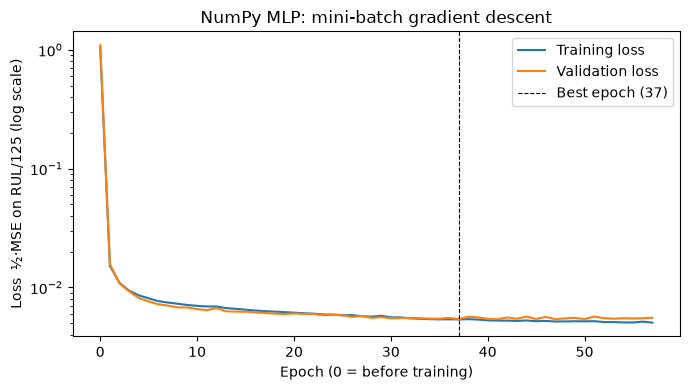

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(history['train_loss'], label='Training loss')
ax.plot(history['val_loss'], label='Validation loss')
ax.axvline(info['best_epoch'], color='k', ls='--', lw=0.8, label=f"Best epoch ({info['best_epoch']})")
ax.set_yscale('log'); ax.set(xlabel='Epoch (0 = before training)', ylabel='Loss  ½·MSE on RUL/125 (log scale)',
       title='NumPy MLP: mini-batch gradient descent')
ax.legend()
fig.tight_layout(); fig.savefig(FIG / 'fig06_numpy_mlp_loss.png', dpi=150); plt.show()

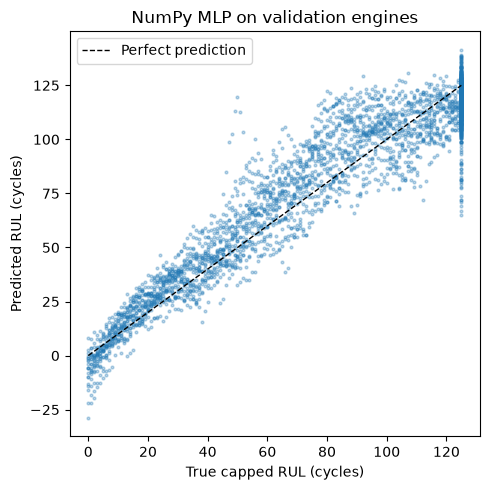

In [7]:
pred = model.predict(X_va) * SCALE
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_va * SCALE, pred, s=4, alpha=0.3)
ax.plot([0, SCALE], [0, SCALE], 'k--', lw=1, label='Perfect prediction')
ax.set(xlabel='True capped RUL (cycles)', ylabel='Predicted RUL (cycles)', title='NumPy MLP on validation engines')
ax.legend()
fig.tight_layout(); fig.savefig(FIG / 'fig07_numpy_mlp_val_scatter.png', dpi=150); plt.show()

**Interpretation.** The loss falls by about two orders of magnitude, and validation loss tracks training loss closely until it flattens, so early stopping takes effect before obvious overfitting. Predictions are tightest at low RUL, where degradation is visible in the sensors; around the cap the model under-predicts many healthy windows (spread roughly 65–140 cycles), because the early part of a trajectory carries little degradation signal. In the mid-range (about 40–100 cycles) predictions sit mostly **above** the diagonal. These are *late* (over-optimistic) predictions, the costly kind for maintenance, so this is a key pattern for the T4 asymmetric score and error analysis. A few predictions near failure are negative, so the inference pipeline (T5b) should clip outputs at 0.

## T2d — Numerical diagnosis

**Check 1: overfit a tiny batch.** If forward, loss, gradients and updates are all correct, a 961-parameter network must be able to memorise 16 examples, driving the loss towards zero. Full-batch GD, learning rate 0.05, fixed 3000 epochs, no early stopping.

**Check 2: learning-rate sweep.** The same model trained on the full training split with learning rates 0.005, 0.05 and 0.5 (max 60 epochs), to show what failure to converge looks like and that it is detected.

In [8]:
tiny = NumpyMLP(X_tr.shape[1], cfg['n_hidden'], seed=0)
Xt, yt = X_tr[:16], y_tr[:16]
h_tiny, i_tiny = train(tiny, Xt, yt, Xt, yt, lr=0.05, batch_size=16, max_epochs=3000, patience=10**9)
print(f"tiny batch: loss {h_tiny['train_loss'][0]:.4f} -> {h_tiny['train_loss'][-1]:.2e} after {i_tiny['epochs_completed']} epochs")

sweep = {}
with np.errstate(over='ignore', invalid='ignore'):
    for lr in (0.005, 0.05, 0.5):
        m = NumpyMLP(X_tr.shape[1], cfg['n_hidden'], seed=0)
        sweep[lr] = train(m, X_tr, y_tr, X_va, y_va, lr, cfg['batch_size'], 60, 10**9)
        print(f"lr={lr:<6} status={sweep[lr][1]['status']:<11} epochs={sweep[lr][1]['epochs_completed']:<3} "
              f"last train loss={sweep[lr][0]['train_loss'][-1]:.4g}")

tiny batch: loss 0.9074 -> 4.29e-05 after 3000 epochs


lr=0.005  status=max_epochs  epochs=60  last train loss=0.007658


lr=0.05   status=max_epochs  epochs=60  last train loss=0.005373
lr=0.5    status=diverged    epochs=1   last train loss=nan


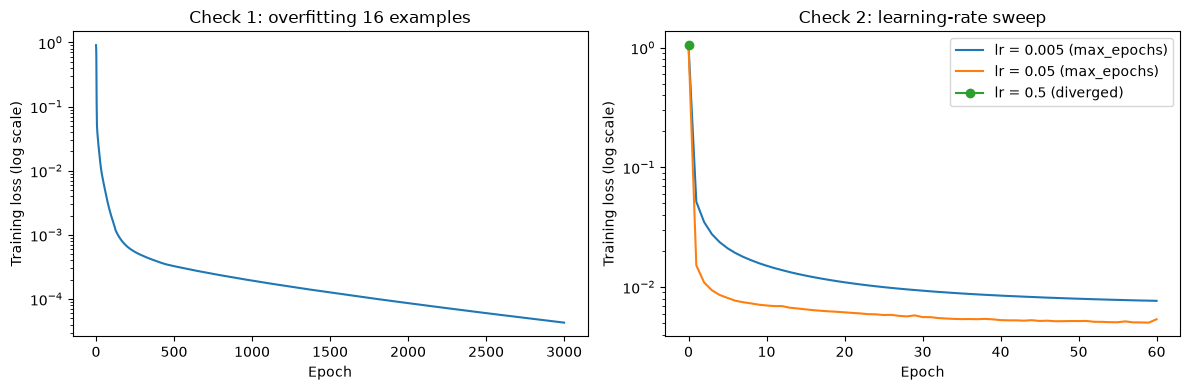

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h_tiny['train_loss'])
ax[0].set_yscale('log'); ax[0].set(xlabel='Epoch', ylabel='Training loss (log scale)', title='Check 1: overfitting 16 examples')
for lr, (h, i) in sweep.items():
    vals = np.array(h['train_loss'], dtype=float)
    ax[1].plot(np.where(np.isfinite(vals), vals, np.nan), marker='o' if i['status'] == 'diverged' else None,
               label=f"lr = {lr} ({i['status']})")
ax[1].set_yscale('log'); ax[1].set(xlabel='Epoch', ylabel='Training loss (log scale)', title='Check 2: learning-rate sweep')
ax[1].legend()
fig.tight_layout(); fig.savefig(FIG / 'fig08_numpy_mlp_diagnosis.png', dpi=150); plt.show()

**Interpretation.**

- *Tiny batch.* The loss falls by more than four orders of magnitude, so the network can memorise data. Together with the gradient check, this rules out a broken backward pass or update rule. It says nothing about generalisation: memorising 16 examples is exactly what we do *not* want on real data.
- *Learning rate 0.005* converges, but slowly: after 60 epochs the loss is still above the lr = 0.05 run.
- *Learning rate 0.5* **diverges in the first epoch**: the loss becomes non-finite and the stopping rule reports `diverged` instead of silently returning garbage weights. The steps overshoot the minimum and ReLU activations grow without bound.
- *Input scaling.* In an earlier run without standardising the summary features, validation RMSE was 20.45 cycles. The slopes were about 100× smaller than the means, so their gradients and their influence were negligible. Standardising with training-engine statistics reduced it to about 13 cycles. This decision used validation data only.